# Lab 5: Hierarchical and DBSCAN Clustering
**Name:** Minh Le  
**Course:** Advanced Big Data and Data Mining (MSCS-634-M50), Fall 2026  
**Dataset:** scikit-learn Wine

This lab compares agglomerative hierarchical clustering and DBSCAN, examines their
parameter sensitivity, and evaluates how the resulting groups relate to wine cultivars.
All clustering and distance-based evaluation use the 13 standardized features.
The known cultivar labels are reserved for external evaluation and reference plots;
they are not inputs to clustering or parameter selection.

## Step 1: Data preparation and exploration
The Wine dataset contains chemical measurements for 178 wines from three cultivars.
We inspect the raw data before standardizing each feature to mean zero and unit
population variance. Otherwise, large-scale variables such as proline can dominate
Euclidean distance. This is exploratory clustering of the entire dataset, so no
train/test split is used and no claim about unseen-sample prediction is made.

In [1]:
from pathlib import Path
import sys
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
OUT = Path('results')
OUT.mkdir(exist_ok=True)
wine = load_wine(as_frame=True)
X = wine.data.copy()
y = wine.target.copy()
print(f'Observations: {X.shape[0]}; features: {X.shape[1]}')
display(X.head())
X.info()
display(X.describe().T)
print('Missing values:', int(X.isna().sum().sum()))
print('Duplicate feature rows:', int(X.duplicated().sum()))
display(y.value_counts().sort_index().rename_axis('Cultivar').to_frame('Count'))

Observations: 178; features: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: float64(13)
m

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Missing values: 0
Duplicate feature rows: 0


,Count
Cultivar,
0,59
1,71
2,48


,Mean after scaling,Std after scaling (ddof=0)
alcohol,-0.0,1.0
malic_acid,-0.0,1.0
ash,-0.0,1.0
alcalinity_of_ash,-0.0,1.0
magnesium,-0.0,1.0
total_phenols,0.0,1.0
flavanoids,-0.0,1.0
nonflavanoid_phenols,0.0,1.0
proanthocyanins,-0.0,1.0
color_intensity,0.0,1.0


Two-component PCA retains 55.41% of total variance.


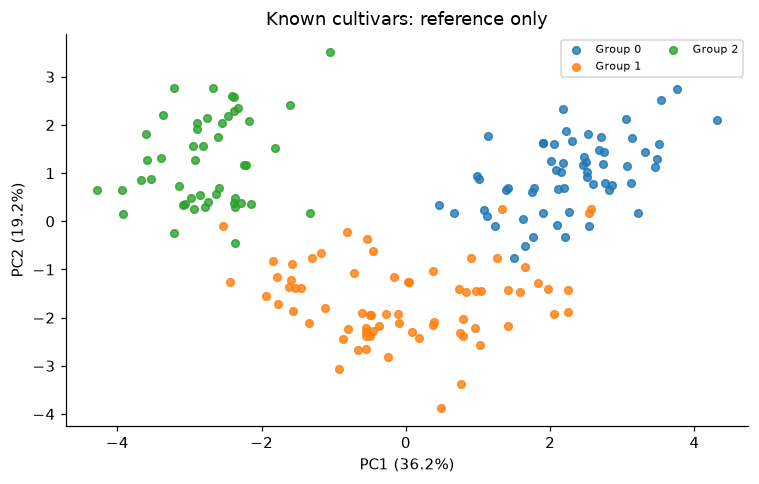

In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
display(pd.DataFrame({'Mean after scaling': X_scaled.mean(axis=0),
                      'Std after scaling (ddof=0)': X_scaled.std(axis=0)}, index=X.columns).round(6))

# PCA is for plotting only; clustering retains all 13 standardized features.
pca = PCA(n_components=2, svd_solver='full')
X_plot = pca.fit_transform(X_scaled)
print(f'Two-component PCA retains {pca.explained_variance_ratio_.sum():.2%} of total variance.')

def plot_clusters(ax, labels, title):
    labels = np.asarray(labels)
    for label in sorted(set(labels) - {-1}):
        mask = labels == label
        ax.scatter(X_plot[mask, 0], X_plot[mask, 1], s=25, alpha=.8,
                   color=plt.get_cmap('tab10')(int(label) % 10), label=f'Group {label}')
    noise = labels == -1
    if noise.any():
        ax.scatter(X_plot[noise, 0], X_plot[noise, 1], c='black', marker='x',
                   s=35, linewidths=1.1, label=f'Noise ({noise.sum()})')
    ax.set(title=title, xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
           ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    ax.legend(fontsize=7, loc='best', ncol=2)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_clusters(ax, y, 'Known cultivars: reference only')
save_figure(fig, '01_cultivars.png')

The data have no missing values or duplicate feature rows, so neither imputation
nor row removal is needed. The first two PCs retain approximately **55.41%** of
variance. Their scatter plot helps visualize broad groups, but overlap or separation
in this projection does not fully represent distances in the 13-feature space.

### Evaluation conventions
- **Silhouette** ranges from -1 to 1; larger values suggest better separation relative
  to within-cluster distances. It requires at least two groups and fewer groups than samples.
- **Homogeneity** ranges from 0 to 1 and measures whether each predicted group contains
  only one true class. **Completeness** measures whether members of each true class stay
  in the same predicted group. Both use cultivar labels only after fitting.
- DBSCAN silhouette excludes noise (`-1`) and is undefined when fewer than two real
  clusters remain. We show undefined scores as `NaN`, never as zero.
- Primary homogeneity and completeness use **all 178 samples**, treating `-1` as a
  predicted category. This convention preserves coverage but does not mean noise is
  a real cluster. We also report scores restricted to assigned samples.
- An all-noise run has completeness 1 under the all-sample convention because every
  class is in the same category; this is a degenerate result, not successful clustering.

In [3]:
def safe_silhouette(features, labels):
    n_groups = len(np.unique(labels))
    return silhouette_score(features, labels) if 2 <= n_groups < len(labels) else np.nan

def evaluate(labels):
    labels = np.asarray(labels)
    assigned = labels != -1
    return {
        'clusters': len(np.unique(labels[assigned])),
        'noise_count': int((~assigned).sum()),
        'coverage': float(assigned.mean()),
        'silhouette_assigned': safe_silhouette(X_scaled[assigned], labels[assigned]),
        'homogeneity_all': homogeneity_score(y, labels),
        'completeness_all': completeness_score(y, labels),
        'homogeneity_assigned': homogeneity_score(y[assigned], labels[assigned]) if assigned.any() else np.nan,
        'completeness_assigned': completeness_score(y[assigned], labels[assigned]) if assigned.any() else np.nan,
    }

## Step 2: Hierarchical clustering
Ward linkage repeatedly merges the pair of groups that causes the smallest increase
in within-cluster variance. We test `n_clusters=2, 3, 4, 5, 6` using Euclidean distance.
The representative cluster count is selected by the highest silhouette, without
consulting the cultivar labels.

,n_clusters,clusters,noise_count,coverage,silhouette_assigned,homogeneity_all,completeness_all,homogeneity_assigned,completeness_assigned
0,2,2,0,1.0,0.2670,0.4441,0.7745,0.4441,0.7745
1,3,3,0,1.0,0.2774,0.7904,0.7825,0.7904,0.7825
2,4,4,0,1.0,0.2258,0.7904,0.6490,0.7904,0.6490
3,5,5,0,1.0,0.1867,0.8106,0.5762,0.8106,0.5762
4,6,6,0,1.0,0.1797,0.8348,0.5530,0.8348,0.5530


Highest-silhouette cluster count: 3


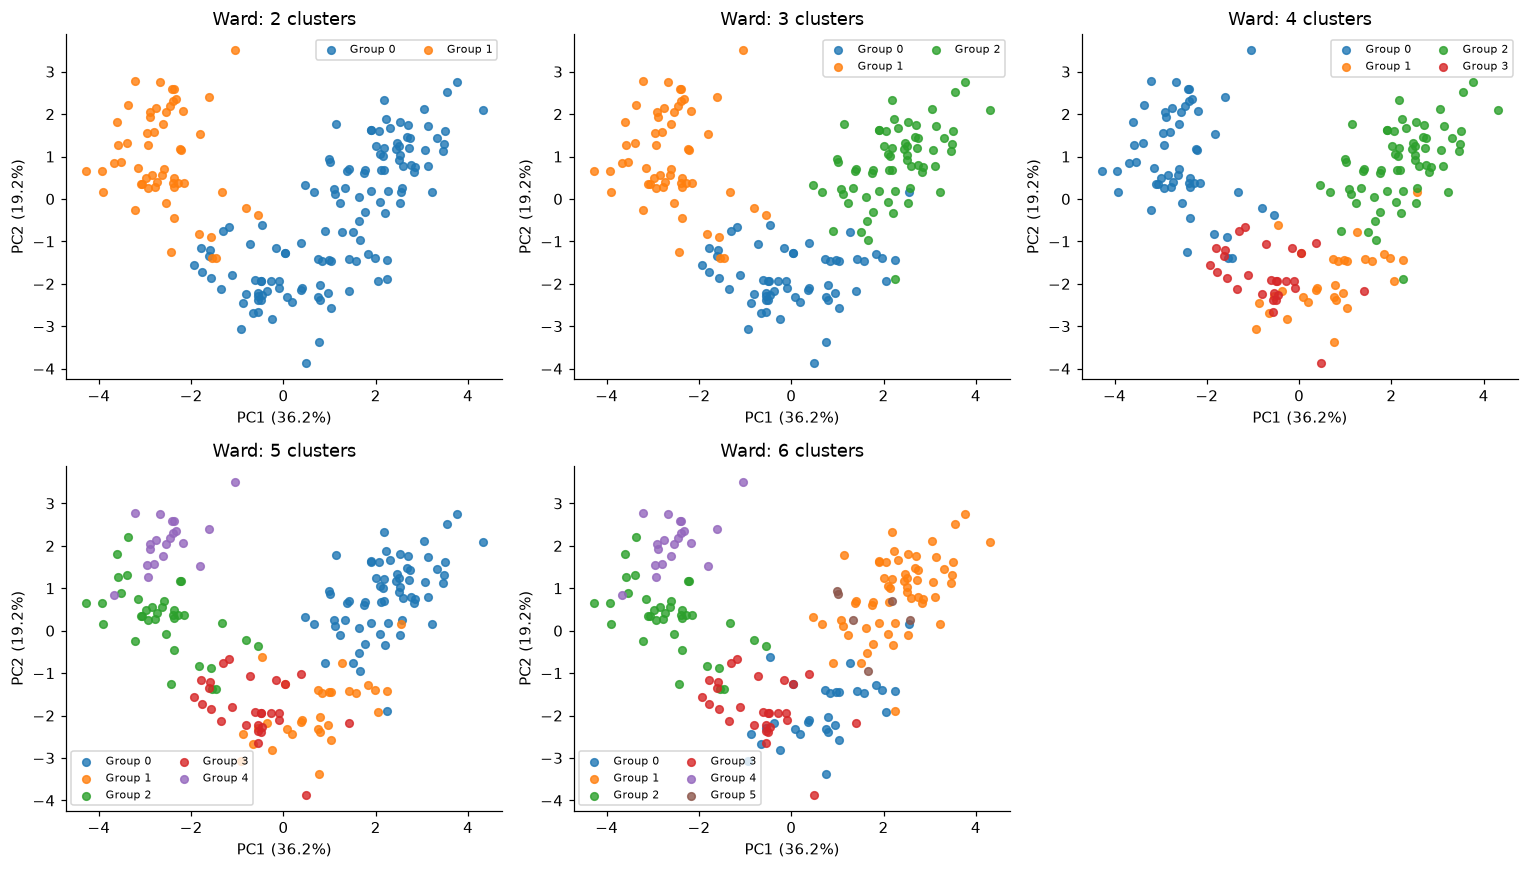

In [4]:
ward_labels = {}
ward_rows = []
for k in range(2, 7):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    ward_labels[k] = labels
    ward_rows.append({'n_clusters': k, **evaluate(labels)})
ward_results = pd.DataFrame(ward_rows)
ward_results.to_csv(OUT / 'hierarchical_metrics.csv', index=False)
display(ward_results.round(4))
best_k = int(ward_results.loc[ward_results.silhouette_assigned.idxmax(), 'n_clusters'])
print('Highest-silhouette cluster count:', best_k)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, k in zip(axes.flat, range(2, 7)):
    plot_clusters(ax, ward_labels[k], f'Ward: {k} clusters')
axes.flat[-1].axis('off')
save_figure(fig, '02_hierarchical_clusters.png')

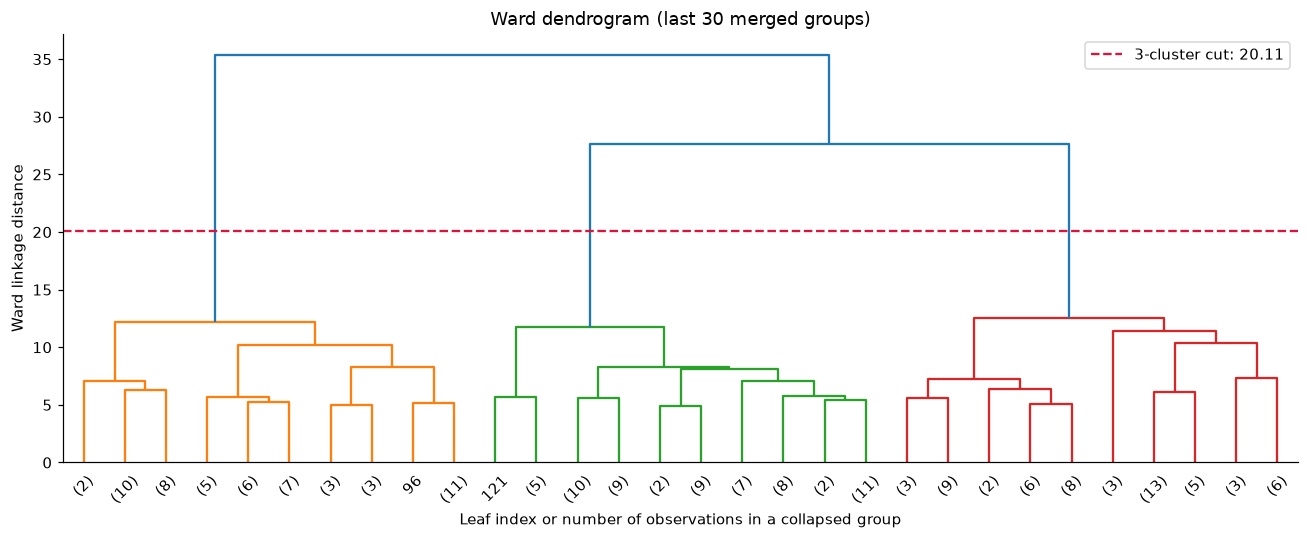

Last five merge heights: [11.722 12.231 12.567 27.652 35.402]


In [5]:
# SciPy Ward linkage uses the same scaled observations and Euclidean geometry.
Z = linkage(X_scaled, method='ward', metric='euclidean')
cut_height = (Z[-3, 2] + Z[-2, 2]) / 2
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True,
           color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, color='crimson', linestyle='--', label=f'3-cluster cut: {cut_height:.2f}')
ax.set(title='Ward dendrogram (last 30 merged groups)',
       xlabel='Leaf index or number of observations in a collapsed group',
       ylabel='Ward linkage distance')
ax.legend()
save_figure(fig, '03_dendrogram.png')
print('Last five merge heights:', np.round(Z[-5:, 2], 3))

### Hierarchical interpretation
Three clusters give the highest tested silhouette (**0.2774**), compared with **0.2670**
for two clusters. Homogeneity and completeness at three clusters are **0.7904** and
**0.7825**, indicating substantial, but imperfect, agreement with cultivars.
Increasing the count to six raises homogeneity to **0.8348** while reducing completeness
to **0.5530**: smaller groups become purer but split members of the same cultivar.

The dendrogram has a large jump from **12.57** (four to three groups) to **27.65**
(three to two groups), followed by the final merge at **35.40**. A cut near **20.11**
therefore yields three groups, consistent with the silhouette comparison. Heights
describe Ward linkage dissimilarity, not raw single-feature differences. The truncated
leaves summarize some earlier merges; parenthesized counts represent collapsed groups.

## Step 3: DBSCAN clustering
DBSCAN grows groups from dense neighborhoods. `eps` is the neighborhood radius in
standardized 13-dimensional space; `min_samples` is the required neighborhood size,
including the point itself. Unassigned observations receive the noise label `-1`.

We inspect sorted neighbor distances and test 15 combinations:
`eps` in **[1.5, 2.0, 2.5, 3.0, 3.5]** and `min_samples` in **[3, 5, 10]**.
The broad grid deliberately includes sparse and merged outcomes. As a transparent
illustrative selection rule, choose the highest assigned-sample silhouette among
runs with at least two real clusters and **at least 70% coverage**. This threshold
limits selection of tiny dense subsets; it is a heuristic, not a universal optimum.

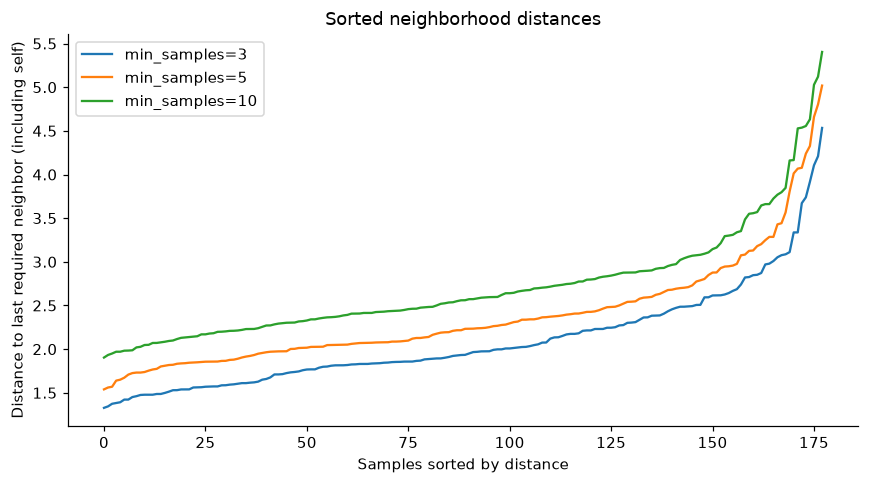

,eps,min_samples,clusters,noise_count,coverage,silhouette_assigned,homogeneity_all,completeness_all,homogeneity_assigned,completeness_assigned
0,1.5,3,8,147,0.1742,0.3311,0.1892,0.2510,1.0000,0.4319
1,2.0,3,5,64,0.6404,0.2113,0.4423,0.3724,0.5801,0.6273
2,2.5,3,1,23,0.8708,NaN,0.0668,0.1885,0.0000,1.0000
3,3.0,3,2,7,0.9607,0.2392,0.0311,0.1347,0.0156,0.1919
4,3.5,3,2,3,0.9831,0.2308,0.0293,0.1866,0.0151,0.1896
5,1.5,5,0,178,0.0000,NaN,0.0000,1.0000,NaN,NaN
6,2.0,5,5,85,0.5225,0.2405,0.3624,0.3247,0.5858,0.6056
7,2.5,5,1,24,0.8652,NaN,0.0576,0.1581,0.0000,1.0000
8,3.0,5,1,11,0.9382,NaN,0.0309,0.1446,0.0000,1.0000
9,3.5,5,1,6,0.9663,NaN,0.0293,0.2162,0.0000,1.0000


Selected DBSCAN: eps=2.5, min_samples=10


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for m in [3, 5, 10]:
    # Passing X explicitly includes the point itself, matching DBSCAN's convention.
    distances, _ = NearestNeighbors(n_neighbors=m).fit(X_scaled).kneighbors(X_scaled)
    ax.plot(np.sort(distances[:, -1]), label=f'min_samples={m}')
ax.set(title='Sorted neighborhood distances', xlabel='Samples sorted by distance',
       ylabel='Distance to last required neighbor (including self)')
ax.legend()
save_figure(fig, '04_neighbor_distances.png')

db_labels = {}
db_rows = []
for m in [3, 5, 10]:
    for eps in [1.5, 2.0, 2.5, 3.0, 3.5]:
        labels = DBSCAN(eps=eps, min_samples=m).fit_predict(X_scaled)
        db_labels[(eps, m)] = labels
        db_rows.append({'eps': eps, 'min_samples': m, **evaluate(labels)})
db_results = pd.DataFrame(db_rows)
db_results.to_csv(OUT / 'dbscan_metrics.csv', index=False)
display(db_results.round(4))
eligible = db_results[(db_results.clusters >= 2) & (db_results.coverage >= .70)
                      & db_results.silhouette_assigned.notna()]
assert not eligible.empty, 'No DBSCAN run meets the illustrative selection rule.'
chosen = eligible.sort_values('silhouette_assigned', ascending=False).iloc[0]
best_eps, best_m = float(chosen.eps), int(chosen.min_samples)
selected_db = db_labels[(best_eps, best_m)]
print(f'Selected DBSCAN: eps={best_eps}, min_samples={best_m}')

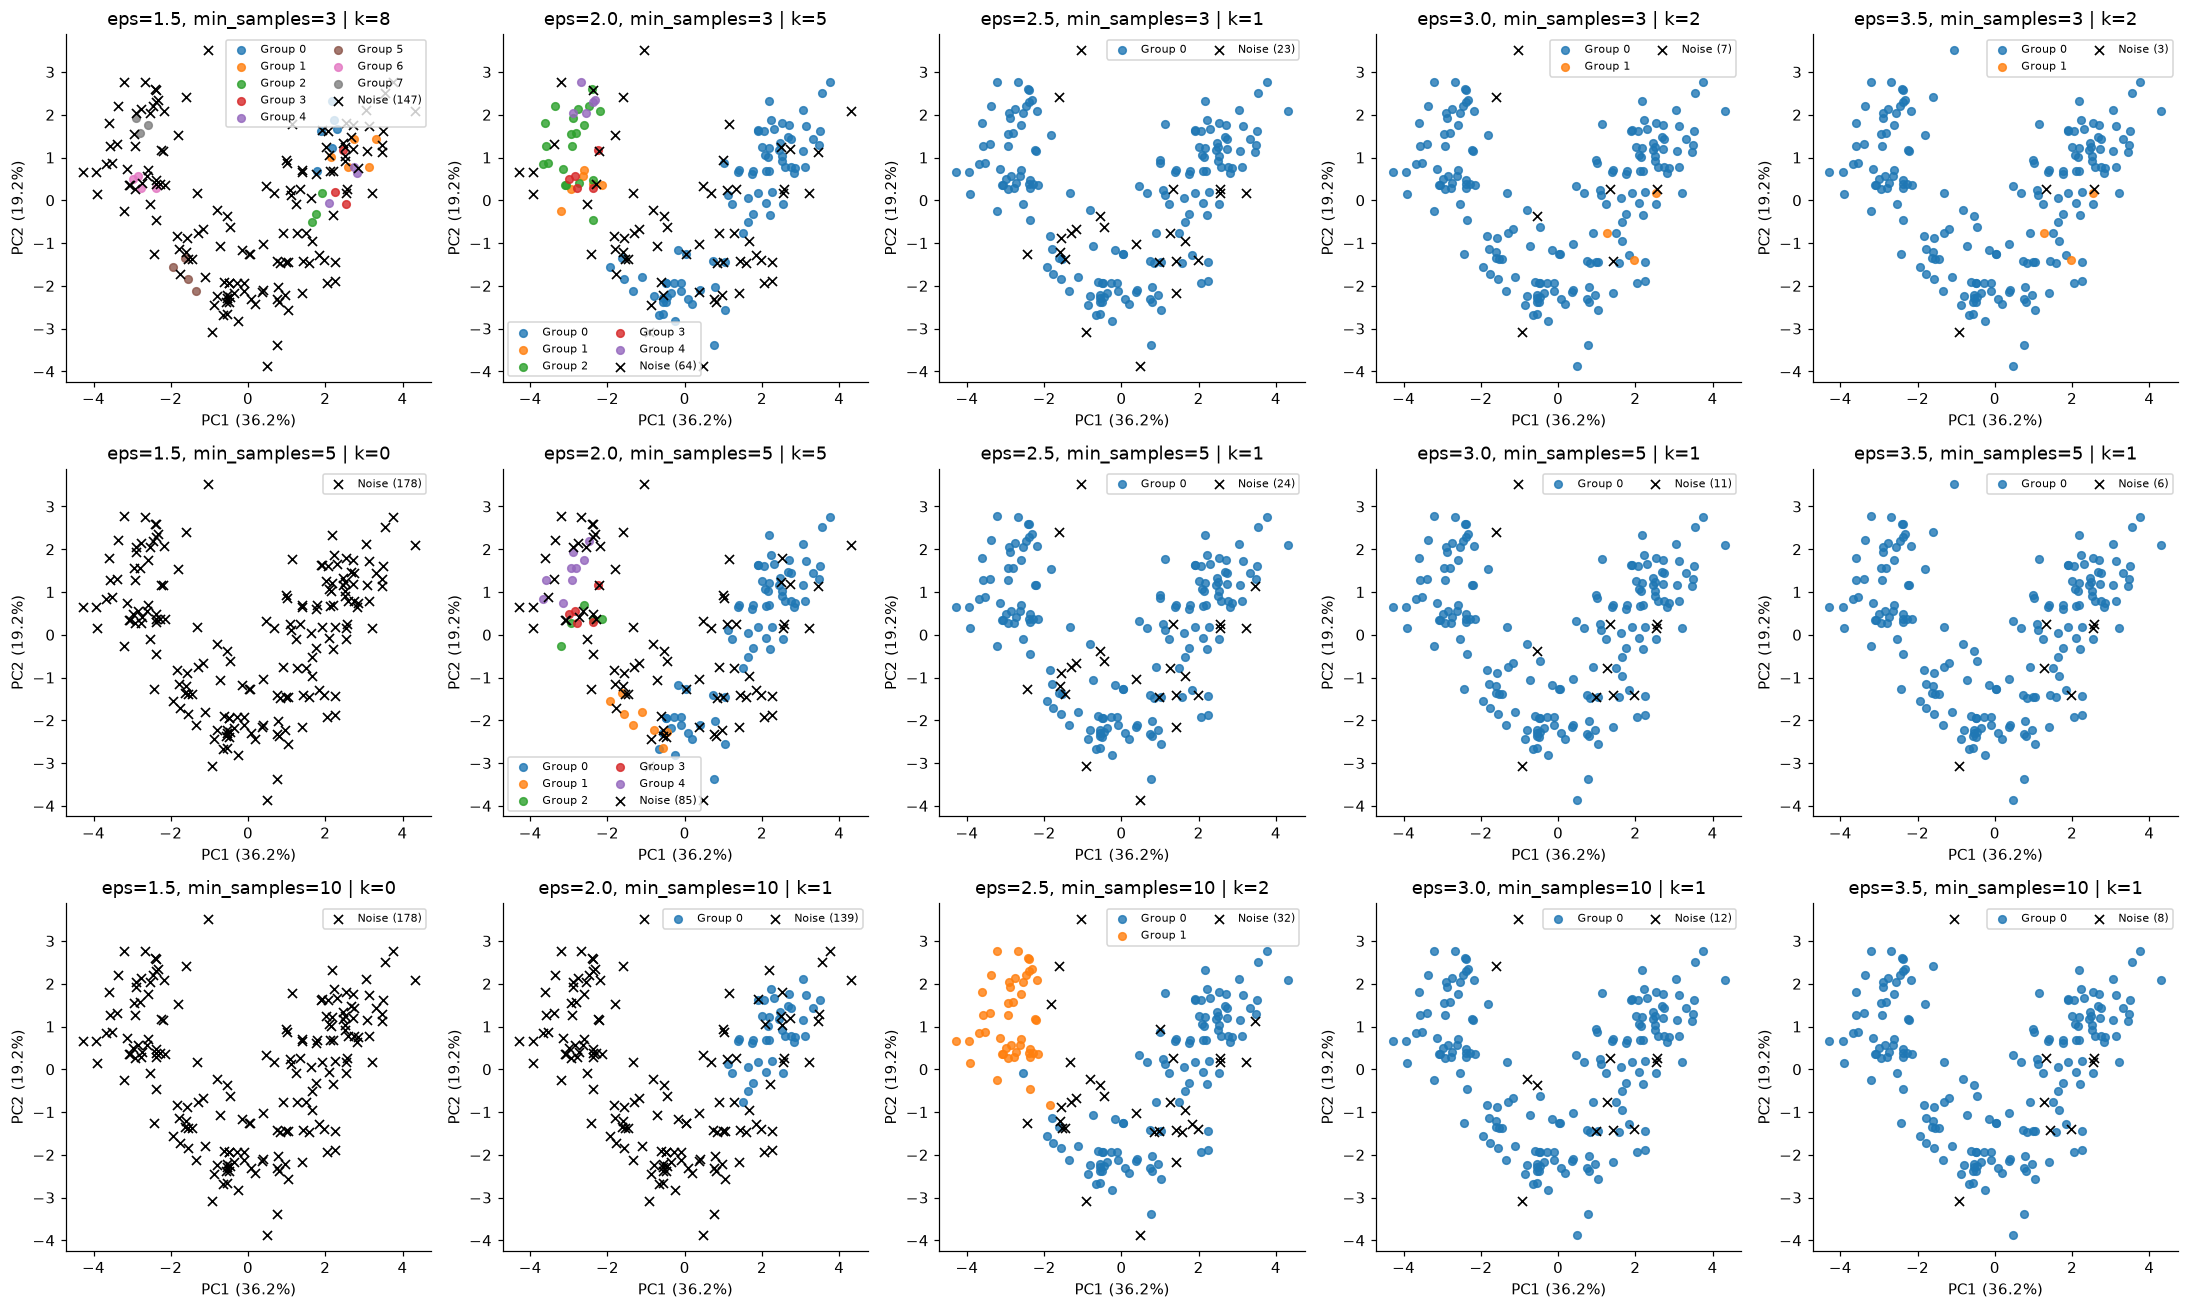

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for row, m in enumerate([3, 5, 10]):
    for col, eps in enumerate([1.5, 2.0, 2.5, 3.0, 3.5]):
        labels = db_labels[(eps, m)]
        k = len(set(labels) - {-1})
        plot_clusters(axes[row, col], labels, f'eps={eps}, min_samples={m} | k={k}')
save_figure(fig, '05_dbscan_parameter_grid.png')

### DBSCAN interpretation
- At `eps=1.5, min_samples=5` or `10`, all **178 observations** are noise. The
  radius is too restrictive for these density requirements in standardized feature space.
- At `eps=1.5, min_samples=3`, eight small groups yield silhouette **0.3311**,
  but **147 observations (82.6%)** are noise. This score describes only 31 wines,
  so choosing it solely because it is highest would discard most of the dataset.
- At `eps=2.0`, increasing `min_samples` from 3 to 5 to 10 increases noise from
  **64 to 85 to 139** samples. The real cluster count changes from **5 to 5 to 1**.
- The selection rule chooses `eps=2.5, min_samples=10`: **2 clusters**, **32 noise
  points**, **82.0% coverage**, and assigned-sample silhouette **0.3228**.
  All-sample homogeneity is **0.5045** and completeness is **0.5604**.
- With `min_samples=10`, increasing `eps` to 3.0 or 3.5 merges the assigned points
  into one group. Its silhouette is undefined even though noise still exists.

Increasing the radius usually retains more observations and can connect previously
separate regions. Increasing the density requirement removes core points and can
break or eliminate groups. Cluster count need not change monotonically because
new groups can also emerge from former noise. The neighbor-distance curves help
identify plausible radii, but do not establish a uniquely correct setting.

## Step 4: Comparison, analysis, and insights
Compare the representatives chosen using the internal criteria above. Because
DBSCAN silhouette excludes noise, its score and the full-data Ward score use different
sample sets. A second comparison evaluates the existing labels from both models on
the same DBSCAN-assigned subset, without refitting either model.

,clusters,noise_count,coverage,silhouette_assigned,homogeneity_all,completeness_all,homogeneity_assigned,completeness_assigned
method,,,,,,,,
Ward (k=3),3,0,1.0000,0.2774,0.7904,0.7825,0.7904,0.7825
"DBSCAN (eps=2.5, min_samples=10)",2,32,0.8202,0.3228,0.5045,0.5604,0.5350,0.9466


,method,samples,silhouette_same_subset
0,Ward,146,0.3491
1,DBSCAN,146,0.3228


Ward cluster,0,1,2
Cultivar,,,
0,0,0,59
1,58,8,5
2,0,48,0


DBSCAN cluster (-1 = noise),-1,0,1
Cultivar,,,
0,3,56,0
1,25,45,1
2,4,0,44


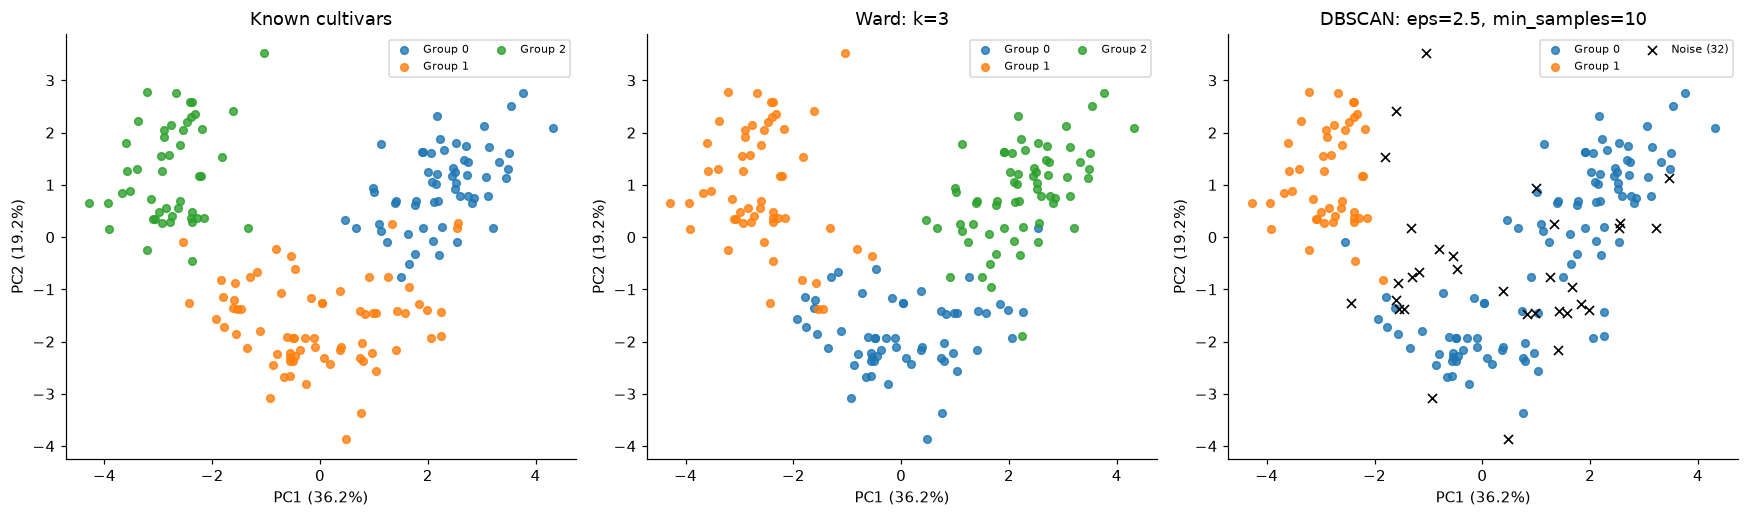

On the same **146 assigned observations**, Ward silhouette is **0.3491** and DBSCAN silhouette is **0.3228**. This subset was selected by DBSCAN, so it is still not an independent validation set.

In [8]:
selected_ward = ward_labels[best_k]
comparison = pd.DataFrame([
    {'method': f'Ward (k={best_k})', **evaluate(selected_ward)},
    {'method': f'DBSCAN (eps={best_eps}, min_samples={best_m})', **evaluate(selected_db)}
]).set_index('method')
display(comparison.round(4))
comparison.to_csv(OUT / 'comparison.csv')

common = selected_db != -1
common_scores = pd.DataFrame({
    'method': ['Ward', 'DBSCAN'],
    'samples': [int(common.sum())] * 2,
    'silhouette_same_subset': [safe_silhouette(X_scaled[common], labels[common])
                               for labels in [selected_ward, selected_db]]
})
display(common_scores.round(4))
common_scores.to_csv(OUT / 'common_subset_metrics.csv', index=False)
display(pd.crosstab(y.rename('Cultivar'), pd.Series(selected_ward, name='Ward cluster')))
display(pd.crosstab(y.rename('Cultivar'), pd.Series(selected_db, name='DBSCAN cluster (-1 = noise)')))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, labels, title in zip(axes, [y, selected_ward, selected_db],
                            ['Known cultivars', f'Ward: k={best_k}',
                             f'DBSCAN: eps={best_eps}, min_samples={best_m}']):
    plot_clusters(ax, labels, title)
save_figure(fig, '06_comparison.png')
pd.DataFrame({'cultivar': y, 'ward_cluster': selected_ward,
              'dbscan_cluster': selected_db, 'PC1': X_plot[:, 0],
              'PC2': X_plot[:, 1]}).to_csv(OUT / 'sample_assignments.csv', index=False)
display(Markdown(f'On the same **{common.sum()} assigned observations**, Ward silhouette is '
                 f'**{common_scores.iloc[0].silhouette_same_subset:.4f}** and DBSCAN silhouette '
                 f'is **{common_scores.iloc[1].silhouette_same_subset:.4f}**. This subset was '
                 'selected by DBSCAN, so it is still not an independent validation set.'))

### Strengths, weaknesses, and conclusions
**Hierarchical clustering** gives a useful multilevel view through the dendrogram
and assigns every observation. For this dataset, three Ward groups best balance
separation and interpretability among the tested counts, with higher all-sample
homogeneity and completeness than the selected DBSCAN run. Its limitations are the
need to choose a cut, sensitivity to feature scaling and outliers, and Ward's
preference for compact groups. Early merges cannot be undone, and computing a
full hierarchy becomes costly as datasets grow.

**DBSCAN** does not require a cluster count and explicitly marks sparse observations
as noise. It can recover irregularly shaped dense groups, but our results show that
one global radius is difficult to tune for these 13-dimensional measurements.
Sparse settings reject many wines, while larger radii connect groups. Noise means
low density under a particular setting, not that a wine is necessarily erroneous.
The selected two-group solution does not reproduce all three cultivars well.

**Overall**, Ward with three groups is the more useful description of cultivar
structure in this experiment. DBSCAN's higher assigned-only silhouette is not
evidence of overall superiority: it omits 32 observations and has weaker agreement
with known cultivars. Cluster identifiers are arbitrary and colors do not imply
class matching across panels; the contingency tables reveal the actual relationships.

### Challenges and decisions
The main challenges were scale differences, visualization of 13 features, DBSCAN
noise handling, and undefined metrics. Standardization makes feature scales
comparable; PCA supplies a consistent plot while fitting retains all features;
explicit coverage and noise conventions make evaluation interpretable. The same
data are used for exploration and evaluation, so parameter-selection scores may be
optimistic. This small fixed grid is illustrative, not an exhaustive search, and the
70% coverage rule is a stated judgment. Silhouette favors compact separated groups
and should be read with the plots and external scores. Future work could examine
alternative linkages, distance choices, and stability under resampling.

## Reproducibility and references
Run all cells from top to bottom with the packages in `requirements.txt`.
The dataset is bundled with scikit-learn; no data download is needed. Outputs are
embedded in this notebook and exported to `results/`. The algorithms used here
are deterministic for a fixed input order and environment; PCA uses full SVD.

- [Wine dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html)
- [Clustering guide and evaluation](https://scikit-learn.org/stable/modules/clustering.html)
- [AgglomerativeClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html)
- [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- [SciPy dendrogram](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html)

In [9]:
packages = ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'scipy', 'nbformat', 'nbclient', 'ipykernel']
print('Python:', sys.version.split()[0])
for package in packages:
    print(f'{package}=={importlib.metadata.version(package)}')
assert X.shape == (178, 13)
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-12)
assert np.allclose(X_scaled.std(axis=0), 1)
assert len(ward_results) == 5 and len(db_results) == 15
assert (db_results.noise_count + (db_results.coverage * len(X)).round().astype(int) == len(X)).all()
print('Data shape, scaling, experiment counts, and coverage checks passed.')

Python: 3.13.2
numpy==2.5.4
pandas==3.0.6
matplotlib==3.11.2
scikit-learn==1.9.1
scipy==1.18.1
nbformat==5.11.1
nbclient==0.11.0
ipykernel==7.4.0
Data shape, scaling, experiment counts, and coverage checks passed.
